# 14 제한 튜닝과 seed 민감도

A/B XGBoost의 깊이2/3/4와 양성 가중치1/약15.77을 비교했습니다. seed42에서 설정을 동결한 뒤43/44 민감도를 확인하고 C 기준도 유지했습니다. 새 CUDA 학습18개와 이전 기준3개 재사용으로 총21개 실행 결과입니다. holdout은 사용하지 않았습니다. 이 Notebook은 저장 결과와 실제 모델을 재검증하며 전체 재학습을 자동 실행하지 않습니다.

In [1]:
from pathlib import Path
import sys,json,hashlib
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
import numpy as np,pandas as pd
from IPython.display import display,Image
from src.common import TABLES,CFG
assert Path(sys.executable).resolve()==Path(CFG['python']).resolve()
OUT=ROOT/'outputs/stage4'
def table(n):return pd.read_parquet(TABLES/('stage4_'+n+'.parquet'))
def figure(n):display(Image(filename=str(ROOT/('outputs/figures/stage4/'+n+'.png'))))
runs=table('training_summary')
assert runs.train_rows.nunique()==runs.validation_all_rows.nunique()==1
assert runs.device.eq('cuda:0').all()
print('실제 실행:',sys.executable,'새 학습:',int((~runs.reused_stage3).sum()),'재사용:',int(runs.reused_stage3.sum()))
display(json.loads((ROOT/'config/stage4_experiment.json').read_text(encoding='utf-8')))

실제 실행: C:\Users\fl27\anaconda3\envs\phm2018\python.exe 새 학습: 18 재사용: 3


{'scheme': 'temporal',
 'cohort': 'common',
 'H': 600,
 'L': 60,
 'grid_families': ['A', 'B'],
 'depths': [2, 3, 4],
 'positive_weights': ['unit', 'sqrt_train_neg_pos'],
 'search_seed': 42,
 'sensitivity_seeds': [42, 43, 44],
 'comparison_budgets_per_10000_raw': [0.5, 5, 10, 20],
 'selection_budgets': [5, 10],
 'selection_rule': 'seed42 grid 전체에서 각 상한별 검출 수 최대, 동률이면 실제 경보 부담 최소, 그 다음 낮은 깊이/단위 가중치/특징 A 순. 두 상한의 선택 설정 합집합(최대2)을 동결. 실제 운영 상한 아님.',
 'sensitivity_reference_configs': ['A_d3_unit', 'B_d3_unit', 'C_d3_unit'],
 'fixed_threshold_test': '각 설정의 seed42에서 고른 상한별 임계값을 seed43/44에 그대로 이전; seed마다 재선택한 결과와 별도 보고',
 'reuse_stage3_baseline': True,
 'unchanged_parameters': 'eta0.05, max1000, subsample/colsample0.8, min_child_weight10, lambda5, max_bin128, aucpr early_stopping50',
 'holdout_scored': False}

## 1. seed42 제한 탐색과 설정 동결

동일 train309,273행, 검증 입력309,203행입니다. 상한5/10에서 설정을 고른 뒤 동결했으며 최고 seed로 사후 교체하지 않았습니다. 양성 가중치는 train의 NEG/POS에서만 계산했습니다.

,selection_budget,config_id,feature_set,depth,weight_mode,run_id,threshold,detected_events,actual_burden
0,5,B_d3_unit,B,3,unit,B_d3_unit_s42,0.006749,13,4.469620
1,10,A_d2_sqrt_train_neg_pos,A,2,sqrt_train_neg_pos,A_d2_sqrt_train_neg_pos_s42,0.089156,21,6.604364


,run_id,config_id,feature_set,model,depth,weight_mode,positive_weight,seed,device,reused_stage3,...,validation_all_rows,validation_known_rows,validation_positive,encoded_features,iterations,train_seconds,AP_known,ROC_AUC_known,log_loss_known,artifact_roundtrip_passed
0,A_d2_unit_s42,A_d2_unit,A,xgboost,2,unit,1.00000,42,cuda:0,False,...,309203,7158,392,233,68,0.573747,0.311415,0.549518,0.283162,True
1,A_d2_sqrt_train_neg_pos_s42,A_d2_sqrt_train_neg_pos,A,xgboost,2,sqrt_train_neg_pos,15.76753,42,cuda:0,False,...,309203,7158,392,233,102,0.499357,0.352697,0.627713,0.207432,True
2,A_d3_unit_s42,A_d3_unit,A,xgboost,3,unit,1.00000,42,cuda:0,True,...,309203,7158,392,233,53,0.000000,0.245622,0.585560,0.279724,True
3,A_d3_sqrt_train_neg_pos_s42,A_d3_sqrt_train_neg_pos,A,xgboost,3,sqrt_train_neg_pos,15.76753,42,cuda:0,False,...,309203,7158,392,233,47,0.429397,0.381319,0.726525,0.211383,True
4,A_d4_unit_s42,A_d4_unit,A,xgboost,4,unit,1.00000,42,cuda:0,False,...,309203,7158,392,233,6,0.314325,0.256085,0.553900,0.296091,True
5,A_d4_sqrt_train_neg_pos_s42,A_d4_sqrt_train_neg_pos,A,xgboost,4,sqrt_train_neg_pos,15.76753,42,cuda:0,False,...,309203,7158,392,233,1,0.299934,0.259144,0.684313,0.249726,True
6,B_d2_unit_s42,B_d2_unit,B,xgboost,2,unit,1.00000,42,cuda:0,False,...,309203,7158,392,257,13,0.772590,0.206229,0.488094,0.294763,True
7,B_d2_sqrt_train_neg_pos_s42,B_d2_sqrt_train_neg_pos,B,xgboost,2,sqrt_train_neg_pos,15.76753,42,cuda:0,False,...,309203,7158,392,257,54,0.697660,0.374046,0.566335,0.208974,True
8,B_d3_unit_s42,B_d3_unit,B,xgboost,3,unit,1.00000,42,cuda:0,True,...,309203,7158,392,257,36,0.000000,0.206897,0.513422,0.277394,True
9,B_d3_sqrt_train_neg_pos_s42,B_d3_sqrt_train_neg_pos,B,xgboost,3,sqrt_train_neg_pos,15.76753,42,cuda:0,False,...,309203,7158,392,257,2,0.546984,0.337706,0.533104,0.246161,True


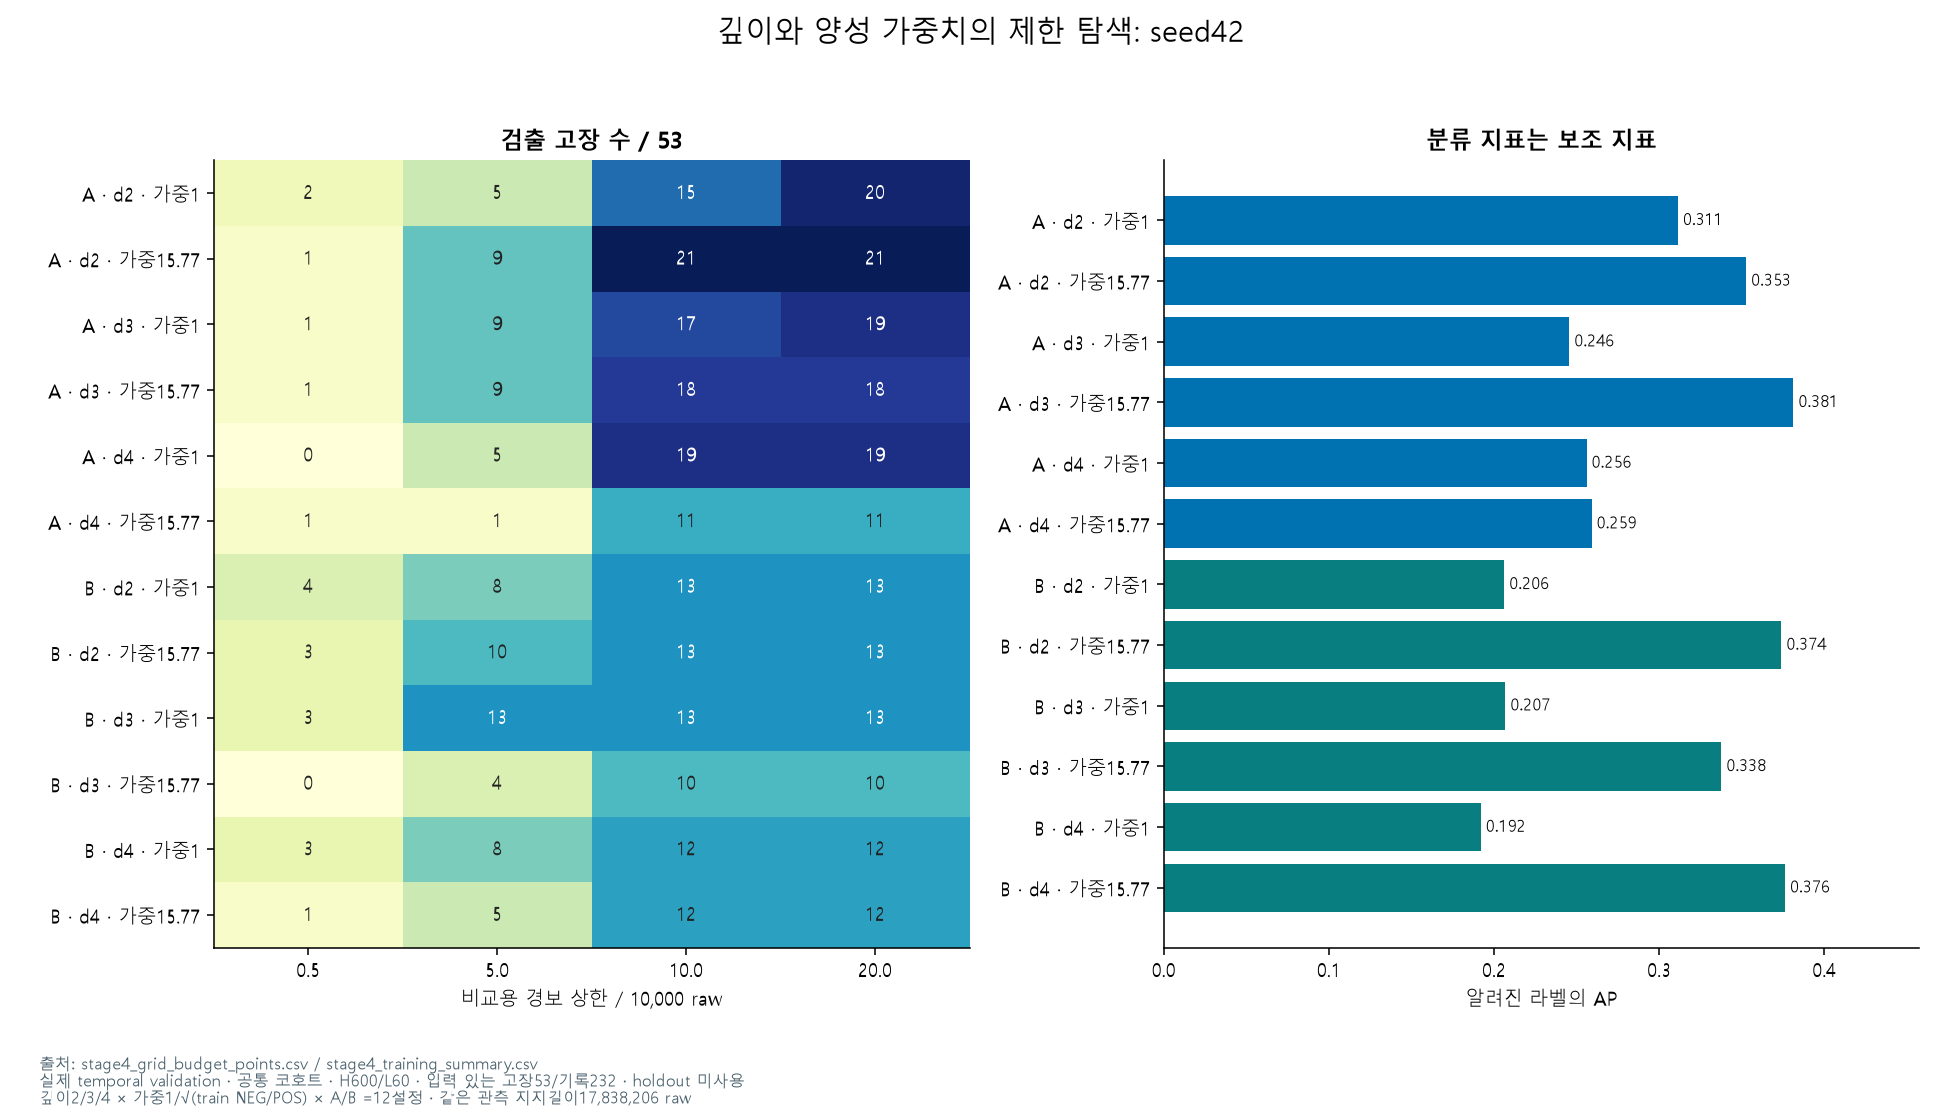

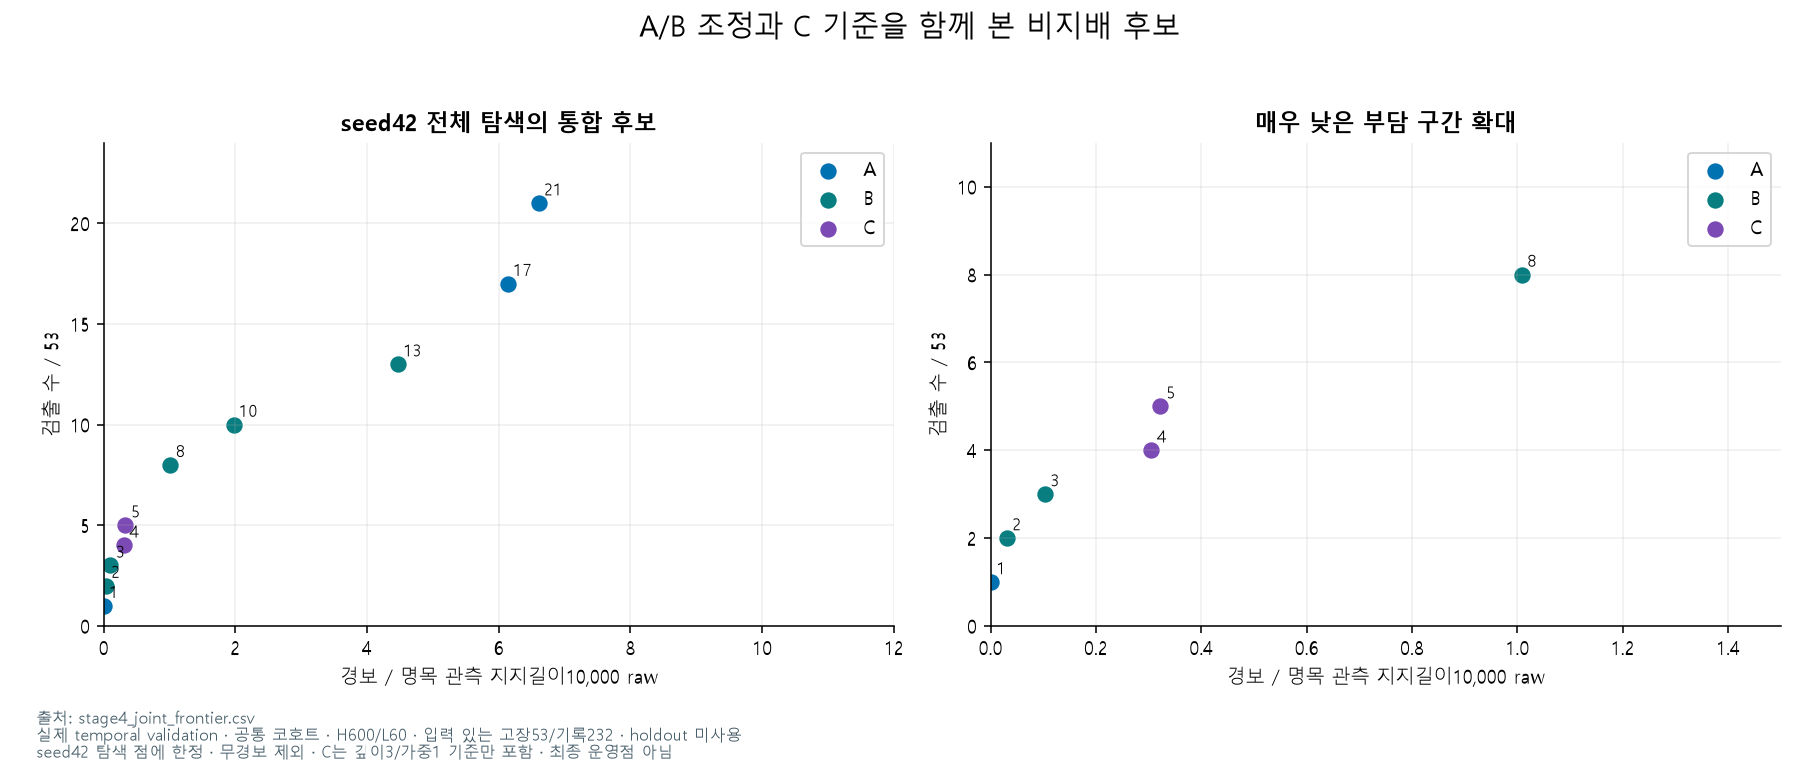

In [2]:
frozen=json.loads((OUT/'selection.json').read_text(encoding='utf-8'))
assert frozen['seed42_only'] and not frozen['holdout_scored']
assert hashlib.sha256((TABLES/'stage4_grid_budget_points.parquet').read_bytes()).hexdigest()==frozen['source_grid_sha256']
display(pd.DataFrame(frozen['selected_by_budget']))
display(runs)
figure('search_grid')
figure('joint_frontier')

## 2. seed마다 임계값을 다시 고른 결과

경보 상한은0.5/5/10/20회/10,000 raw입니다. 실제 운영 허용치가 아니라 비교용 상한입니다. 3seed는 독립 고장 표본 수를 늘리지 않으며 표본은 가용53개/기록232개 그대로입니다.

,config_id,seed,budget_per_10000_raw,threshold,detected_events,recall_available,recall_recorded,alarm_episodes_per_10000_raw
0,A_d2_sqrt_train_neg_pos,42,0.5,0.700000,1.0,0.018868,0.004310,0.001121
1,A_d2_sqrt_train_neg_pos,42,5.0,0.100000,9.0,0.169811,0.038793,4.342926
2,A_d2_sqrt_train_neg_pos,42,10.0,0.089156,21.0,0.396226,0.090517,6.604364
3,A_d2_sqrt_train_neg_pos,42,20.0,0.089156,21.0,0.396226,0.090517,6.604364
4,A_d3_unit,42,0.5,0.040988,1.0,0.018868,0.004310,0.020742
5,A_d3_unit,42,5.0,0.010000,9.0,0.169811,0.038793,3.527821
6,A_d3_unit,42,10.0,0.006907,17.0,0.320755,0.073276,6.135707
7,A_d3_unit,42,20.0,0.004555,19.0,0.358491,0.081897,11.445658
8,B_d3_unit,42,0.5,0.023510,3.0,0.056604,0.012931,0.354856
9,B_d3_unit,42,5.0,0.006749,13.0,0.245283,0.056034,4.469620


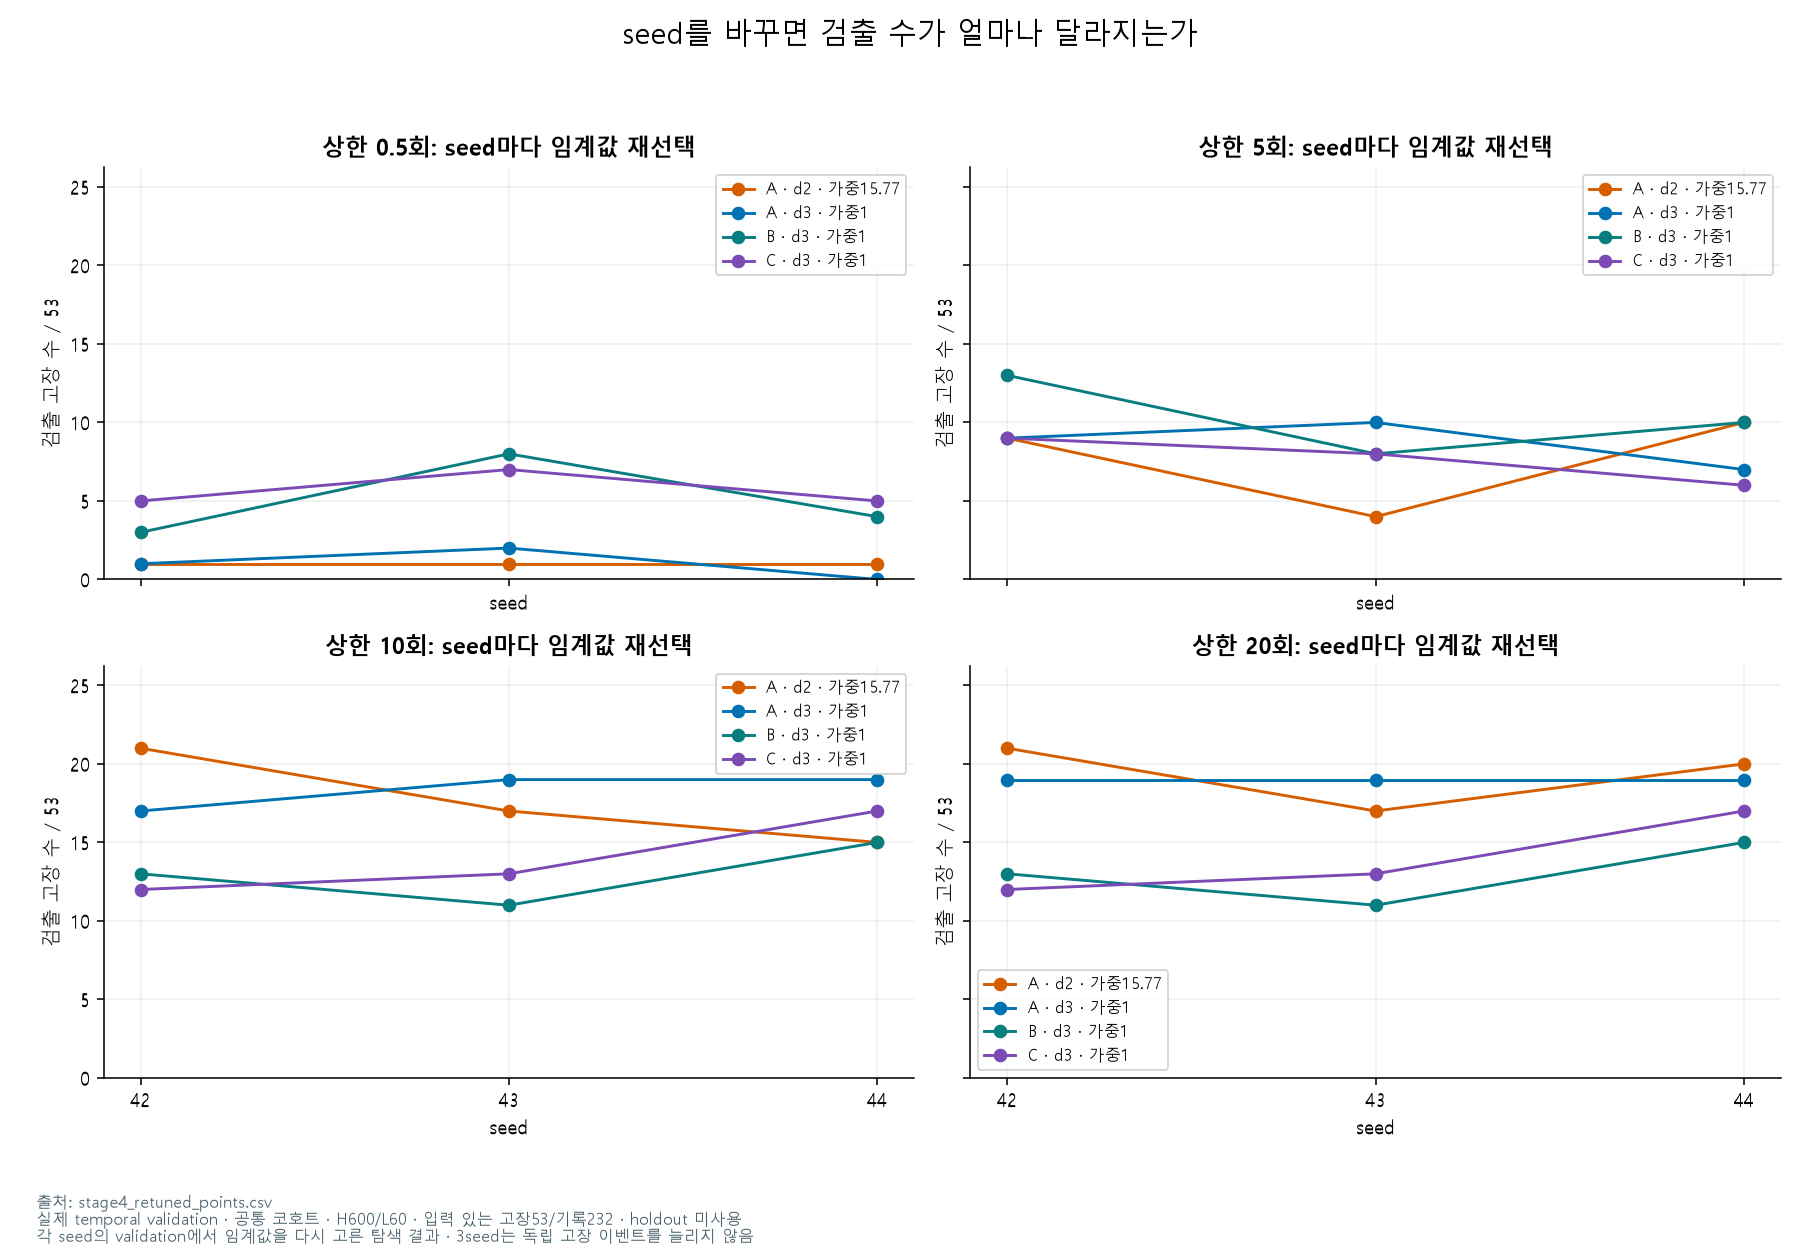

,mode,config_id,budget_per_10000_raw,detected_min,detected_max,detected_mean,burden_min,burden_max,exceeding_seeds
0,retuned,A_d2_sqrt_train_neg_pos,0.5,1.0,1.0,1.000000,0.001121,0.009530,0
1,retuned,A_d2_sqrt_train_neg_pos,5.0,4.0,10.0,7.666667,2.346088,4.342926,0
2,retuned,A_d2_sqrt_train_neg_pos,10.0,15.0,21.0,17.666667,5.997800,8.854029,0
3,retuned,A_d2_sqrt_train_neg_pos,20.0,17.0,21.0,19.333333,6.604364,10.864321,0
4,retuned,A_d3_unit,0.5,0.0,2.0,1.000000,0.000000,0.361023,0
5,retuned,A_d3_unit,5.0,7.0,10.0,8.666667,2.297316,4.022265,0
6,retuned,A_d3_unit,10.0,17.0,19.0,18.333333,5.928287,6.403110,0
7,retuned,A_d3_unit,20.0,19.0,19.0,19.000000,5.928287,11.445658,0
8,retuned,B_d3_unit,0.5,3.0,8.0,5.000000,0.206859,0.455763,0
9,retuned,B_d3_unit,5.0,8.0,13.0,10.333333,0.455763,4.469620,0


In [3]:
retuned=table('retuned_points')
assert retuned.alarm_episodes_per_10000_raw.le(retuned.budget_per_10000_raw).all()
display(retuned[['config_id','seed','budget_per_10000_raw','threshold','detected_events','recall_available','recall_recorded','alarm_episodes_per_10000_raw']])
figure('retuned_seed')
display(table('seed_ranges'))

## 3. seed42 임계값을 그대로 옮긴 결과

43/44에 같은 숫자 임계값을 적용한 뒤 상한 초과나 검출 소실을 그대로 기록했습니다. 상한을 넘지 않는 것만으로 안정적이라고 판단하지 않습니다. B seed43은 상한5/10 기준 이전 시 경보와 검출이0이었습니다.

,config_id,seed,budget_per_10000_raw,threshold,detected_events,alarm_episodes_per_10000_raw,exceeds_budget
0,A_d2_sqrt_train_neg_pos,42,0.5,0.700000,1.0,0.001121,False
1,A_d2_sqrt_train_neg_pos,42,5.0,0.100000,9.0,4.342926,False
2,A_d2_sqrt_train_neg_pos,42,10.0,0.089156,21.0,6.604364,False
3,A_d2_sqrt_train_neg_pos,42,20.0,0.089156,21.0,6.604364,False
4,A_d2_sqrt_train_neg_pos,43,0.5,0.700000,0.0,0.000000,False
5,A_d2_sqrt_train_neg_pos,43,5.0,0.100000,4.0,2.346088,False
6,A_d2_sqrt_train_neg_pos,43,10.0,0.089156,17.0,8.935316,False
7,A_d2_sqrt_train_neg_pos,43,20.0,0.089156,17.0,8.935316,False
8,A_d2_sqrt_train_neg_pos,44,0.5,0.700000,0.0,0.002242,False
9,A_d2_sqrt_train_neg_pos,44,5.0,0.100000,10.0,4.111400,False


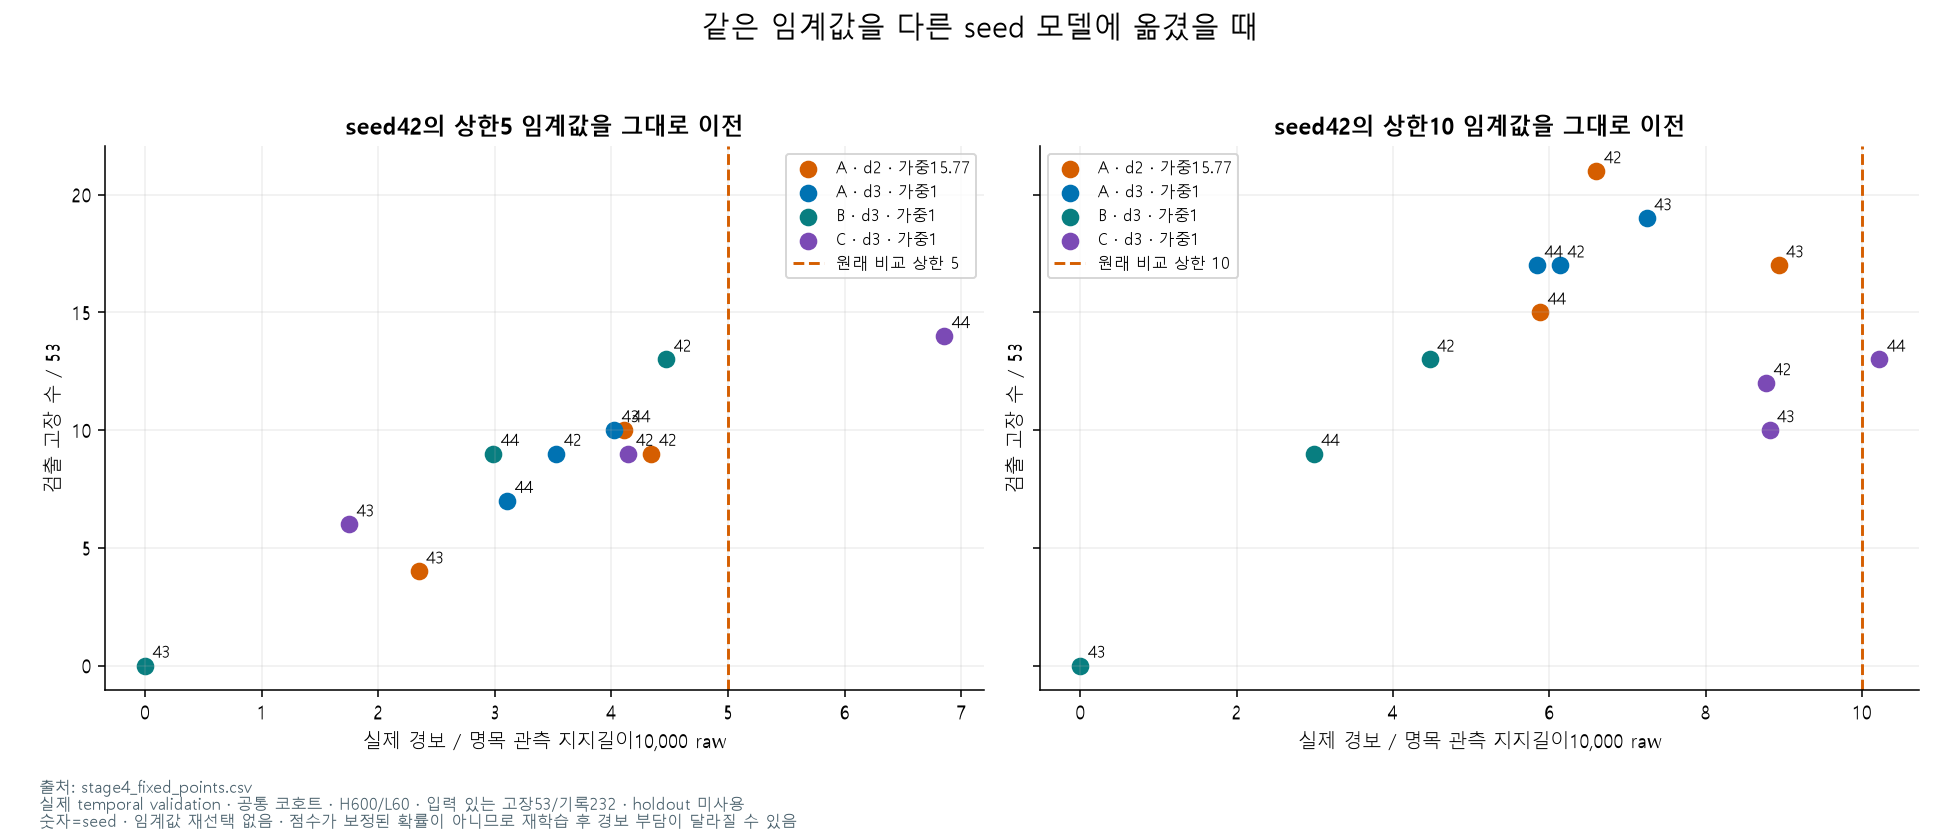

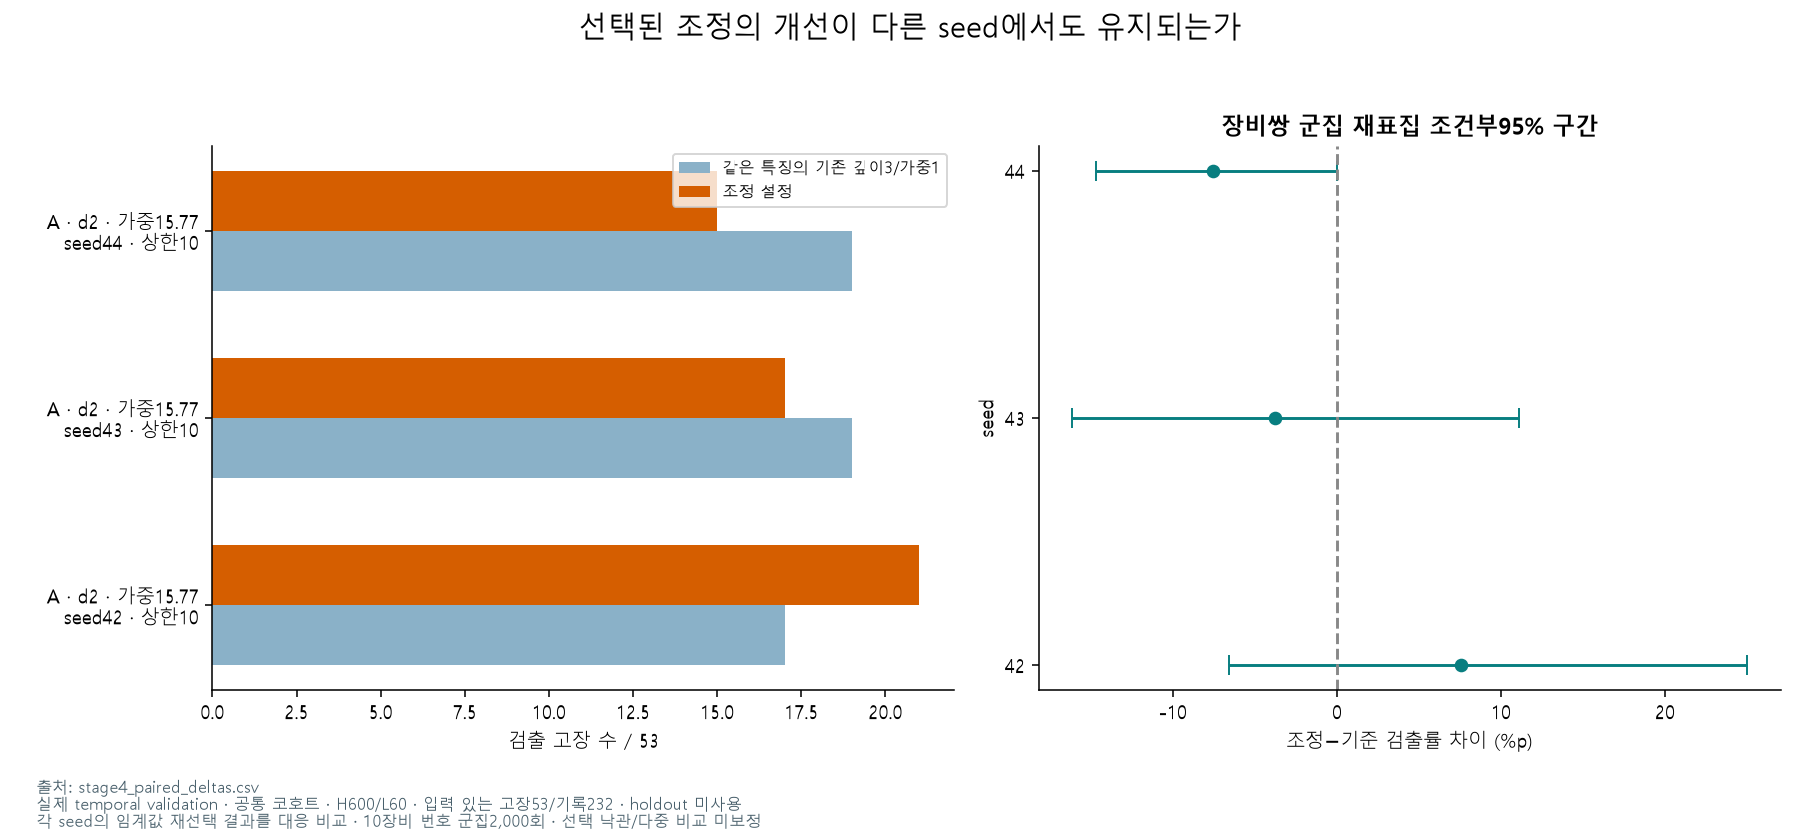

,config_id,baseline_config,seed,budget_per_10000_raw,detected_baseline,detected_tuned,gained_events,lost_events,recall_delta,ci_low,ci_high
0,B_d3_unit,B_d3_unit,42,5,13,13,0,0,0.000000,0.000000,0.000000
1,B_d3_unit,B_d3_unit,43,5,8,8,0,0,0.000000,0.000000,0.000000
2,B_d3_unit,B_d3_unit,44,5,10,10,0,0,0.000000,0.000000,0.000000
3,A_d2_sqrt_train_neg_pos,A_d3_unit,42,10,17,21,8,4,0.075472,-0.065811,0.250000
4,A_d2_sqrt_train_neg_pos,A_d3_unit,43,10,19,17,3,5,-0.037736,-0.161290,0.111111
5,A_d2_sqrt_train_neg_pos,A_d3_unit,44,10,19,15,0,4,-0.075472,-0.147071,0.000000


In [4]:
fixed=table('fixed_points')
for r in fixed.itertuples():
    ref=retuned[retuned.config_id.eq(r.config_id)&retuned.seed.eq(42)&retuned.budget_per_10000_raw.eq(r.budget_per_10000_raw)].iloc[0]
    assert ref.threshold==r.threshold
display(fixed[['config_id','seed','budget_per_10000_raw','threshold','detected_events','alarm_episodes_per_10000_raw','exceeds_budget']])
figure('fixed_threshold')
figure('paired_gain')
display(table('paired_deltas'))

## 4. 실제 이벤트·미확인 경보·로컬 자원

원래의53개 이벤트를 seed별로 대조합니다. NA에서 시작한 경보는 확정 오경보로 해석하지 않습니다. GPU 학습은 순차, CPU 경보 평가는3프로세스를 사용했습니다. 메모리 표본은 약2초 간격으로 순간 최고치를 보장하지 않습니다.

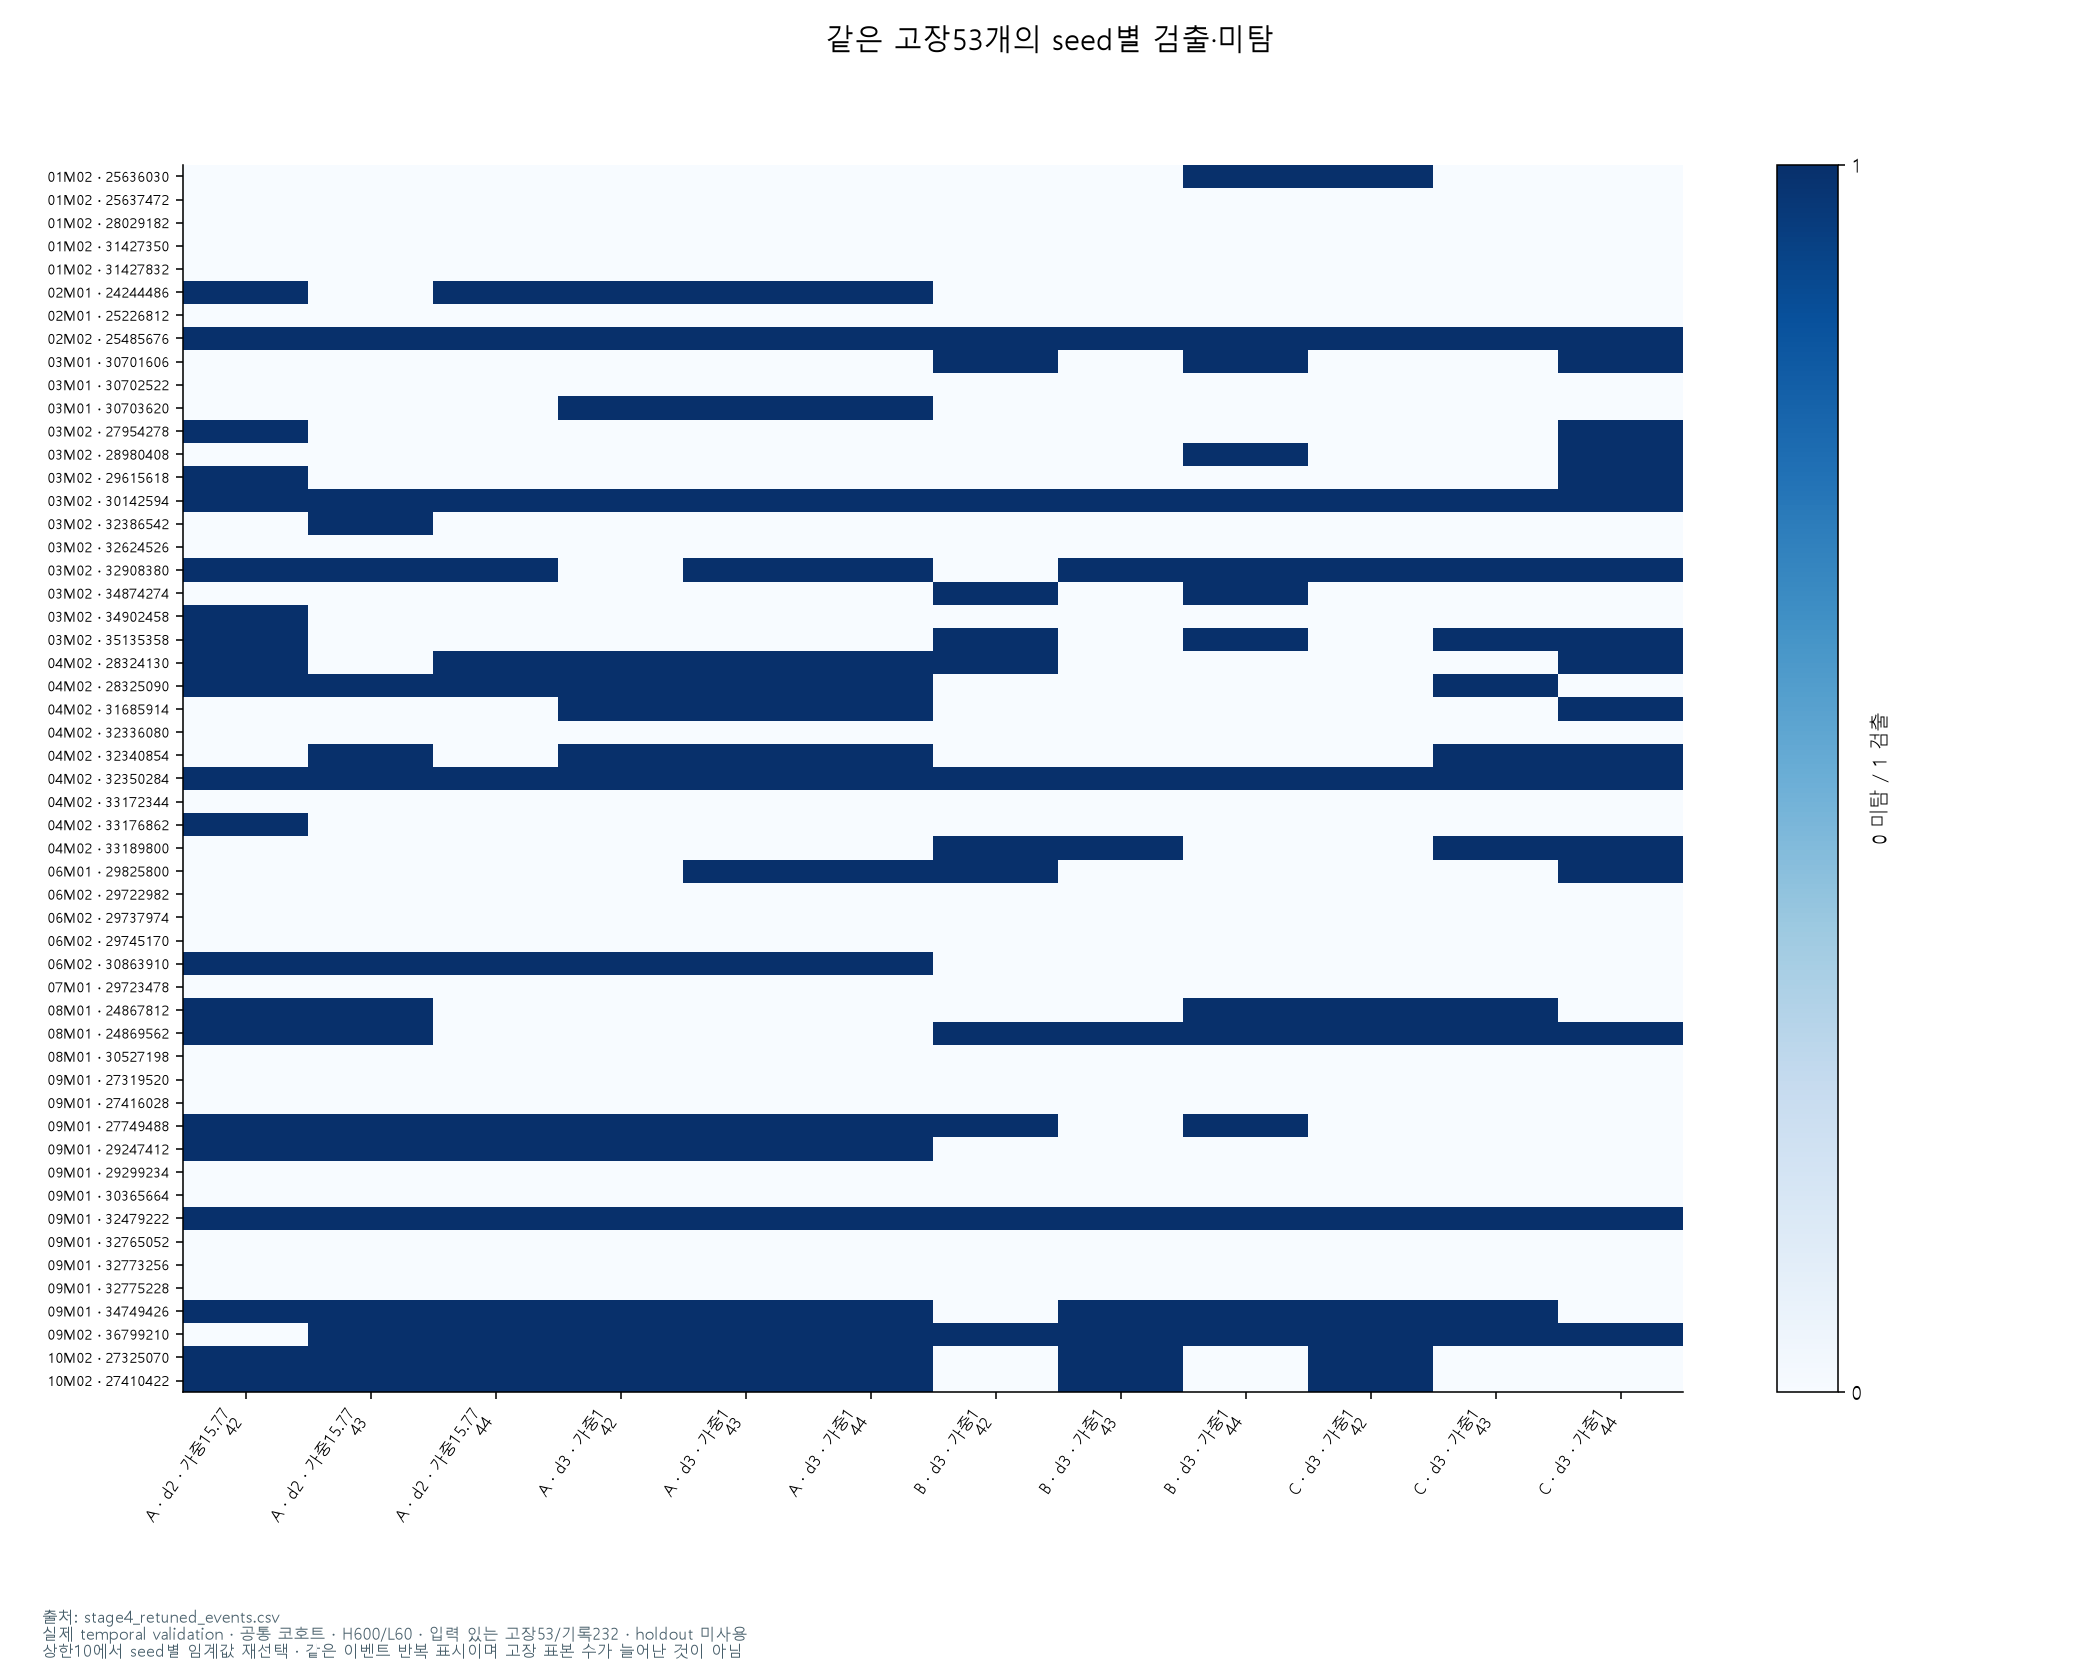

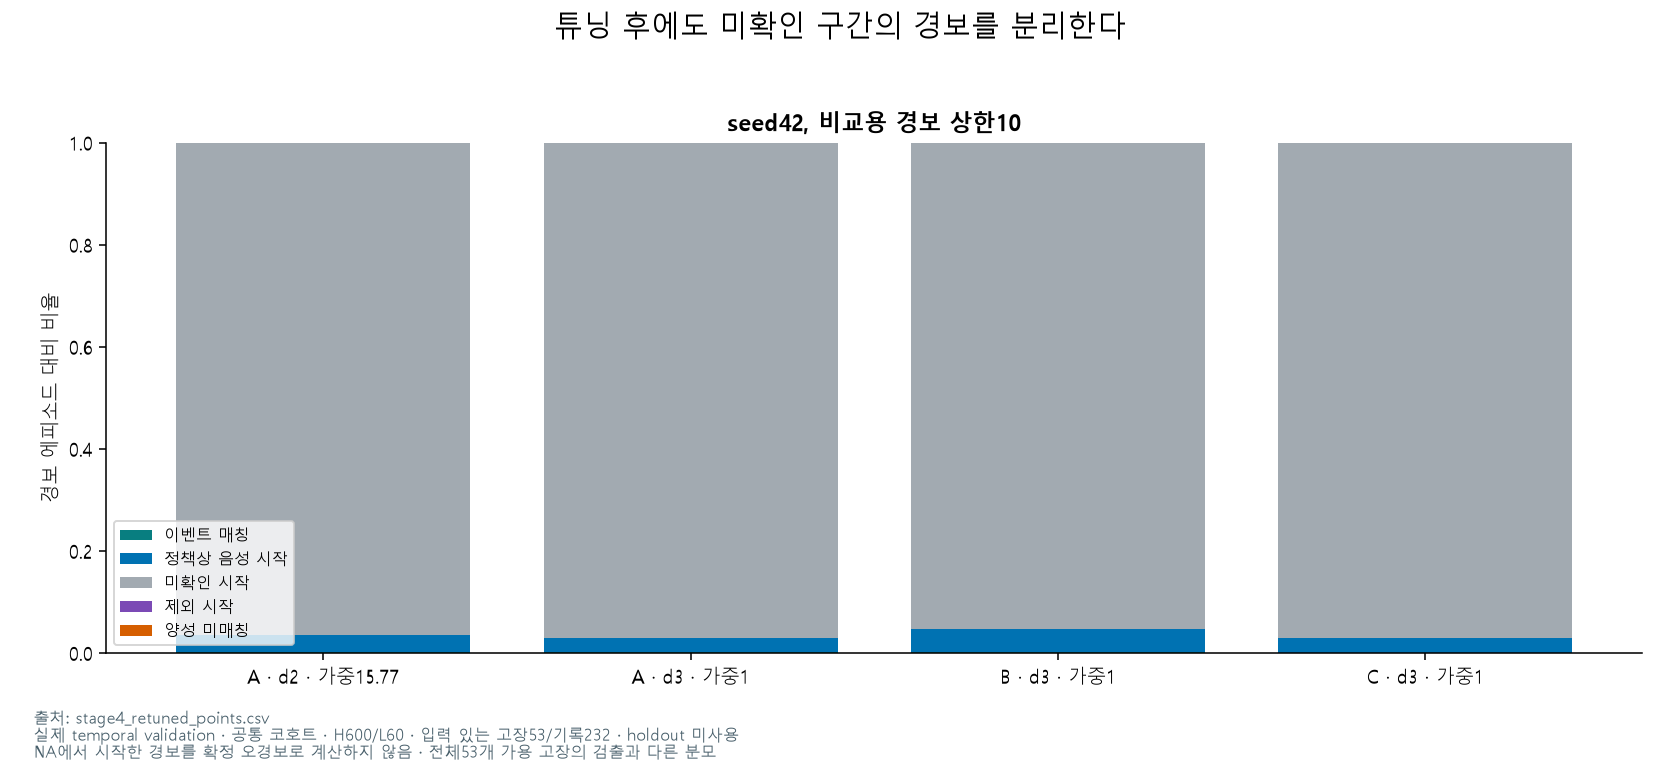

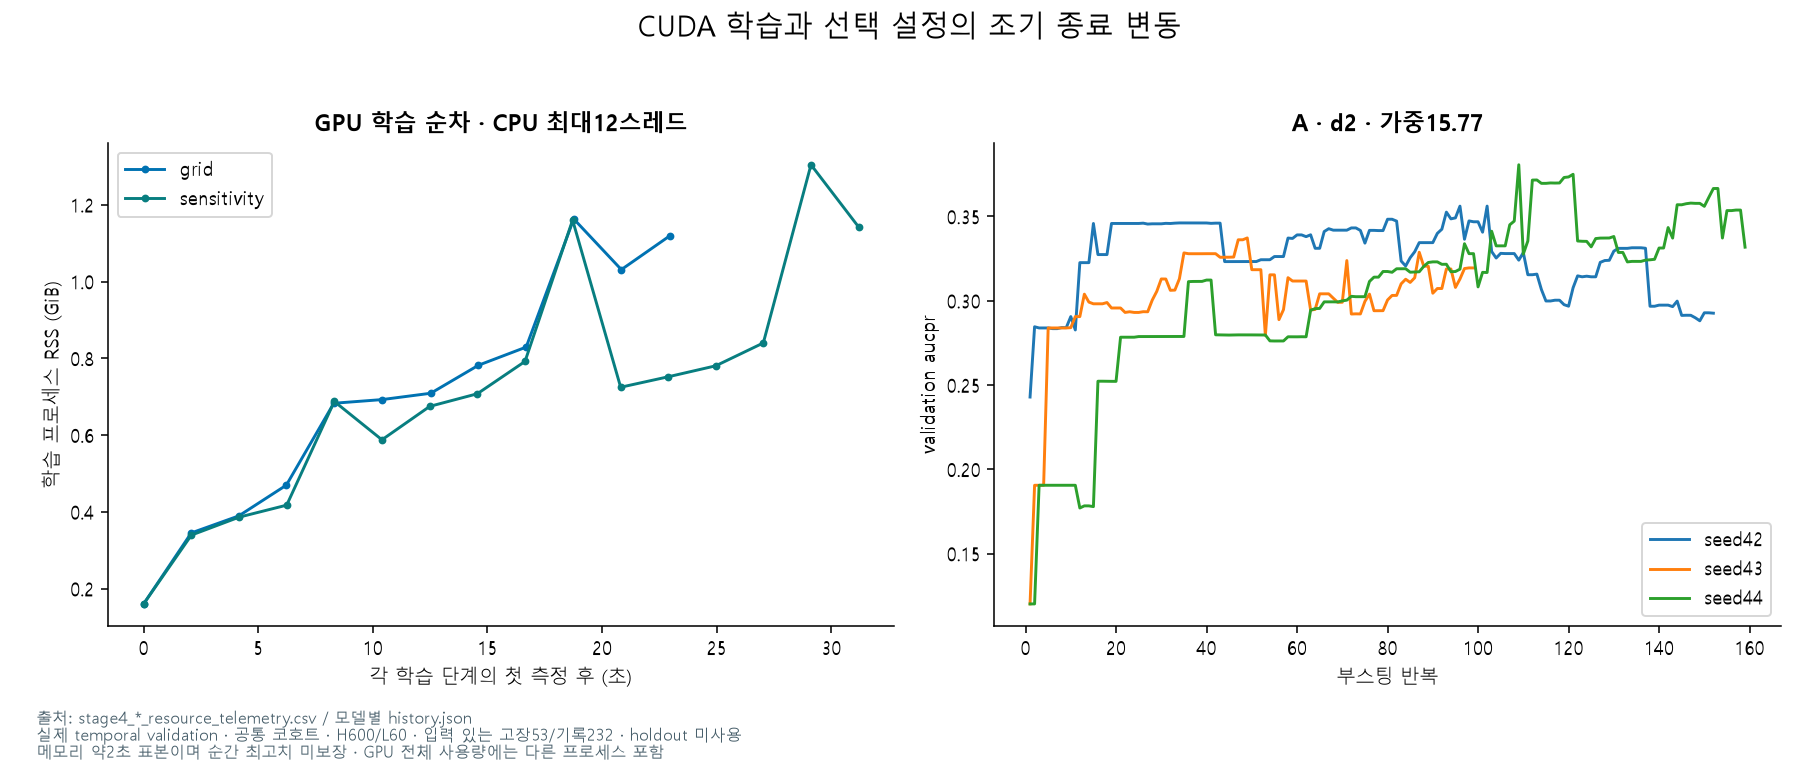

모든 학습 실행의 CUDA 설정 확인: 21


In [5]:
figure('event_matrix')
figure('unknown_alarms')
figure('training_resources')
for r in runs.itertuples():
    cfg=json.loads((OUT/(r.run_id+'_booster_config.json')).read_text(encoding='utf-8'))
    assert cfg['learner']['generic_param']['device']=='cuda:0'
print('모든 학습 실행의 CUDA 설정 확인:',len(runs))

## 5. 모든 저장 모델의 실제 입력 예측 재현

각 특징의 공통 검증 첫 배치128행을 다시 읽습니다. 저장된 train 전용 전처리의 transform만 사용하고 모든21개 모델의 재계산 점수를 원래 저장 점수와 대조합니다.

In [6]:
import joblib,xgboost as xgb
from src.pretraining import iter_scoring_batches
from src.features import schema
reference=None
for f in 'ABC':
    X,meta=next(iter_scoring_batches('temporal','validation',f,600,'common'))
    X=X.iloc[:128];meta=meta.iloc[:128]
    assert list(X)==schema()[f] and not {'time','Tool','audit_label','TTF'} & set(X)
    if reference is None:reference=meta
    else:pd.testing.assert_frame_equal(reference,meta)
    prep=joblib.load(OUT/f'{f}_preprocessor.joblib')
    transformed=prep.transform(X).astype('float32')
    for r in runs[runs.feature_set.eq(f)].itertuples():
        model=joblib.load(OUT/(r.run_id+'.joblib'))
        score=model.get_booster().predict(xgb.DMatrix(transformed),iteration_range=(0,model.best_iteration+1))
        saved=pd.read_parquet(OUT/(r.run_id+'_validation.parquet'),columns=['Tool','time','score'])
        expected=meta[['Tool','time']].merge(saved,on=['Tool','time'],how='left',validate='one_to_one')
        np.testing.assert_allclose(score,expected.score,rtol=1e-6,atol=1e-7)
        print(r.run_id,': 실제 재계산 일치',len(score),'행')

A_d2_unit_s42 : 실제 재계산 일치 128 행
A_d2_sqrt_train_neg_pos_s42 : 실제 재계산 일치 128 행


A_d3_unit_s42 : 실제 재계산 일치 128 행
A_d3_sqrt_train_neg_pos_s42 : 실제 재계산 일치 128 행
A_d4_unit_s42 : 실제 재계산 일치 128 행


A_d4_sqrt_train_neg_pos_s42 : 실제 재계산 일치 128 행
A_d2_sqrt_train_neg_pos_s43 : 실제 재계산 일치 128 행


A_d2_sqrt_train_neg_pos_s44 : 실제 재계산 일치 128 행
A_d3_unit_s43 : 실제 재계산 일치 128 행


A_d3_unit_s44 : 실제 재계산 일치 128 행
B_d2_unit_s42 : 실제 재계산 일치 128 행


B_d2_sqrt_train_neg_pos_s42 : 실제 재계산 일치 128 행
B_d3_unit_s42 : 실제 재계산 일치 128 행
B_d3_sqrt_train_neg_pos_s42 : 실제 재계산 일치 128 행


B_d4_unit_s42 : 실제 재계산 일치 128 행
B_d4_sqrt_train_neg_pos_s42 : 실제 재계산 일치 128 행
B_d3_unit_s43 : 실제 재계산 일치 128 행


B_d3_unit_s44 : 실제 재계산 일치 128 행
C_d3_unit_s42 : 실제 재계산 일치 128 행


C_d3_unit_s43 : 실제 재계산 일치 128 행
C_d3_unit_s44 : 실제 재계산 일치 128 행


## 6. 산출물 검사와 해석

상한10에서 기존 A는17/19/19개, 조정 A는21/17/15개로 개선이 seed43/44에 유지되지 않았습니다. 기존 A/B를 주 기준으로 유지하고 조정 A는 보조 연구 비교로 둡니다. C는 매우 낮은 부담의 참조입니다. 다음은 설정과 임계값 선택 절차를 고정한 장비 그룹 일반화 검증입니다.

현재 validation은 조기 종료/설정/임계값에 재사용했으므로 독립 성능이 아닙니다. 장비쌍 군집 부트스트랩도 선택 낙관과 다중 비교를 보정하지 않습니다. 시간 단위·정비 종료·고장 이력 완전성·확률 보정은 미검증입니다.

In [7]:
checks=json.loads((ROOT/'outputs/validation/stage4_checks.json').read_text(encoding='utf-8'))
assert all(c['passed'] for c in checks['checks'])
assert checks['holdout_scored'] is False
print('실제 산출물 검사 통과:',len(checks['checks']))
print('holdout 점수화:',checks['holdout_scored'])

실제 산출물 검사 통과: 1430
holdout 점수화: False
